In [ ]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [42]:
df = pd.read_csv(Path("../data/2016-building-energy-benchmarking-6af870b7ba821669818300.csv"))
df.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12,88434,0,88434,Hotel,Hotel,88434.0,NaN,NaN,NaN,NaN,NaN,60.0,81.699997,84.300003,182.500000,189.000000,7226362.5,7456910.0,2003882.00,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,NaN,61.0,94.800003,97.900002,176.100006,179.399994,8387933.0,8664479.0,0.00,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41,956110,196718,759392,Hotel,Hotel,756493.0,NaN,NaN,NaN,NaN,NaN,43.0,96.000000,97.699997,241.899994,244.100006,72587024.0,73937112.0,21566554.00,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,7,DOWNTOWN,47.61412,-122.33664,1926,1.0,10,61320,0,61320,Hotel,Hotel,61320.0,NaN,NaN,NaN,NaN,NaN,56.0,110.800003,113.300003,216.199997,224.000000,6794584.0,6946800.5,2214446.25,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,7,DOWNTOWN,47.61375,-122.34047,1980,1.0,18,175580,62000,113580,"Hotel, Parking, Swimming Pool",Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,NaN,75.0,114.800003,118.699997,211.399994,215.600006,14172606.0,14656503.0,0.00,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88


## Répartition par types de bâtiments

Répartition par PrimaryPropertyType

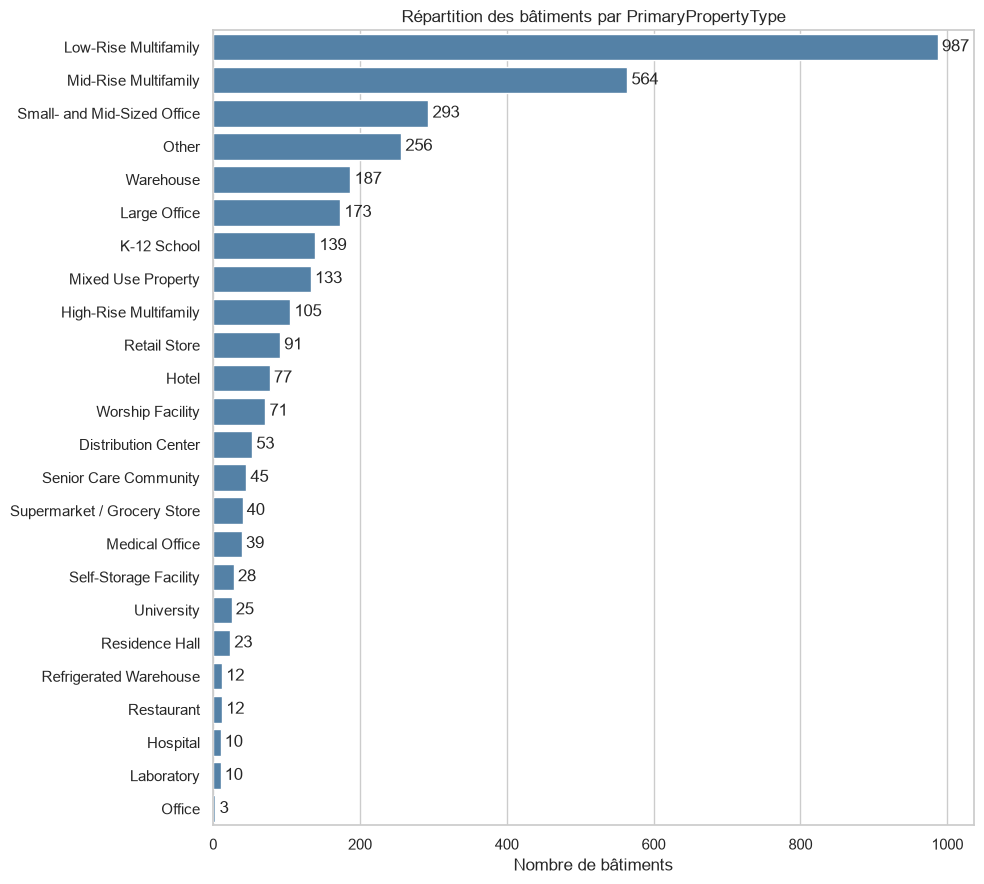

In [43]:
order = df["PrimaryPropertyType"].value_counts().index

fig, ax = plt.subplots(figsize=(10, 9))
sns.countplot(data=df, y="PrimaryPropertyType", order=order, color="steelblue", ax=ax)
ax.bar_label(ax.containers[0], padding=3)
ax.set_title("Répartition des bâtiments par PrimaryPropertyType")
ax.set_xlabel("Nombre de bâtiments")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

Répartition des PropertyName par PrimaryPropertyType

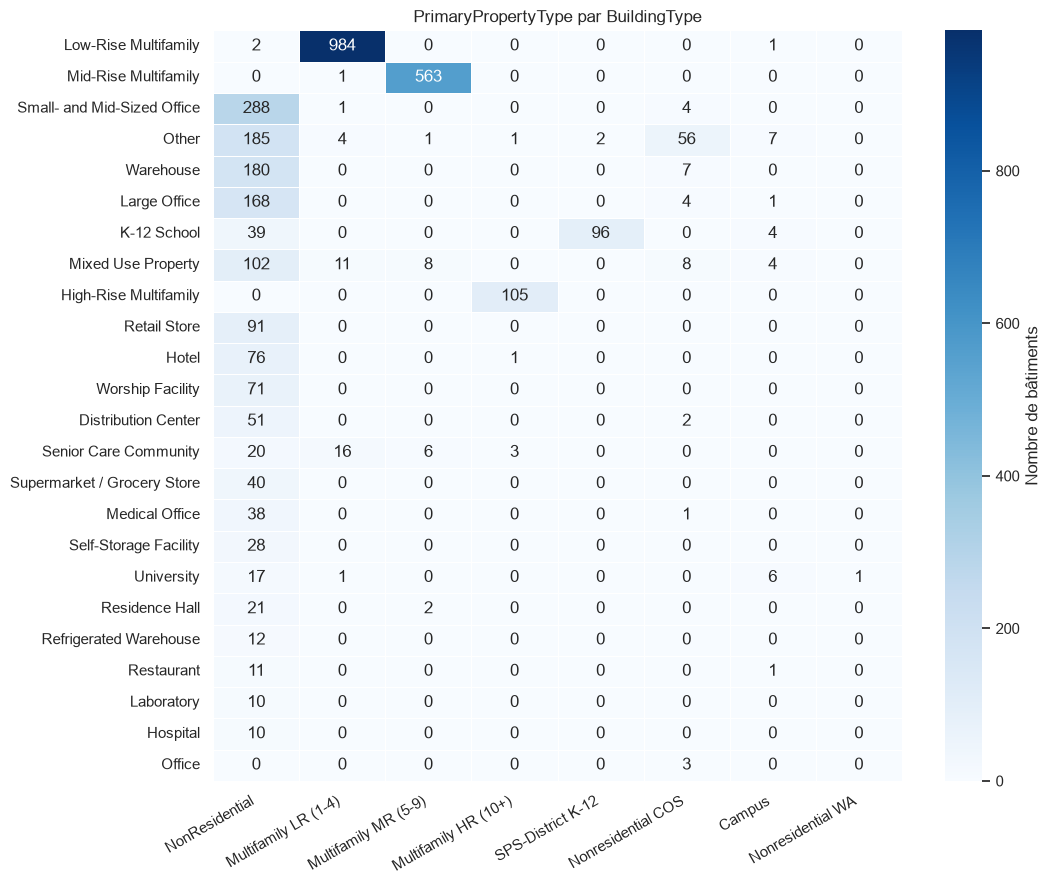

In [44]:
ct = pd.crosstab(df["PrimaryPropertyType"], df["BuildingType"])
ct = ct.loc[ct.sum(axis=1).sort_values(ascending=False).index,
            ct.sum().sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", linewidths=0.5,
            cbar_kws={"label": "Nombre de bâtiments"}, ax=ax)
ax.set_title("PrimaryPropertyType par BuildingType")
ax.set_xlabel("")
ax.set_ylabel("")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## Analyse Géographique

In [45]:
fig = px.density_map(
    df, lat="Latitude", lon="Longitude",
    radius=12, zoom=10.5, height=650,
    center={"lat": df["Latitude"].mean(), "lon": df["Longitude"].mean()},
    map_style="open-street-map",
    title="Concentration des bâtiments à Seattle",
)
fig.show()

In [46]:
print(f"{df['ZipCode'].nunique()} codes postaux distincts ({df['ZipCode'].isna().sum()} valeurs manquantes)")

(df.dropna(subset=["ZipCode"])
   .assign(ZipCode=lambda d: d["ZipCode"].astype(int))
   .groupby("ZipCode")
   .agg(City=("City", lambda s: ", ".join(sorted(s.dropna().unique()))),
        State=("State", lambda s: ", ".join(sorted(s.dropna().unique()))),
        Nombre_de_batiments=("ZipCode", "size"))
   .reset_index())

55 codes postaux distincts (16 valeurs manquantes)


,ZipCode,City,State,Nombre_de_batiments
0,98006,Seattle,WA,1
1,98011,Seattle,WA,1
2,98012,Seattle,WA,1
3,98013,Seattle,WA,2
4,98020,Seattle,WA,1
5,98028,Seattle,WA,1
6,98033,Seattle,WA,1
7,98040,Seattle,WA,1
8,98053,Seattle,WA,1
9,98070,Seattle,WA,1


Répartition des batiments par parcelles

In [47]:
parcels = df["TaxParcelIdentificationNumber"]
counts = parcels.value_counts()
print(f"{parcels.nunique()} numéros de parcelle distincts pour {len(df)} lignes "
      f"({parcels.isna().sum()} valeurs manquantes)")
print(f"{(counts > 1).sum()} parcelles partagées par plusieurs bâtiments")

table = counts.rename_axis("TaxParcelIdentificationNumber").reset_index(name="Nombre de bâtiments")
with pd.option_context("display.max_rows", None):
    display(table.head(80))

3268 numéros de parcelle distincts pour 3376 lignes (0 valeurs manquantes)
77 parcelles partagées par plusieurs bâtiments


,TaxParcelIdentificationNumber,Nombre de bâtiments
0,1625049001,8
1,0002400002,5
2,3224049012,5
3,0925049346,5
4,3624039009,4
5,8632880000,4
6,7666203240,4
7,1985200003,3
8,0164000222,3
9,0939000300,3


Répartition par CouncilDistrictCode

In [48]:
districts = df["CouncilDistrictCode"]
counts = districts.value_counts()
print(f"{districts.nunique()} districts distincts pour {len(df)} lignes "
      f"({districts.isna().sum()} valeurs manquantes)")

table = counts.rename_axis("CouncilDistrictCode").reset_index(name="Nombre de bâtiments")
with pd.option_context("display.max_rows", None):
    display(table.head(80))

7 districts distincts pour 3376 lignes (0 valeurs manquantes)


,CouncilDistrictCode,Nombre de bâtiments
0,7,1037
1,3,596
2,2,509
3,4,367
4,5,338
5,1,282
6,6,247


Répartition par Neighborhood

In [49]:
districts = df["Neighborhood"]
counts = districts.value_counts()
print(f"{districts.nunique()} districts distincts pour {len(df)} lignes "
      f"({districts.isna().sum()} valeurs manquantes)")

table = counts.rename_axis("Neighborhood").reset_index(name="Nombre de bâtiments")
with pd.option_context("display.max_rows", None):
    display(table.head(80))

19 districts distincts pour 3376 lignes (0 valeurs manquantes)


,Neighborhood,Nombre de bâtiments
0,DOWNTOWN,573
1,EAST,453
2,MAGNOLIA / QUEEN ANNE,423
3,GREATER DUWAMISH,375
4,NORTHEAST,280
5,LAKE UNION,251
6,NORTHWEST,210
7,SOUTHWEST,166
8,NORTH,145
9,BALLARD,126


Vision entonnoir de la Map

In [70]:
geo_df = df.assign(
    CouncilDistrictCode="D" + df["CouncilDistrictCode"].astype(str),
    Neighborhood=df["Neighborhood"].str.upper(),
    ZipCode=df["ZipCode"].astype("Int64").astype(str).fillna("Inconnu"),
)

tm = geo_df.assign(
    District="District " + df["CouncilDistrictCode"].astype(str),
    Quartier=df["Neighborhood"].str.title(),
    CodePostal="ZIP " + df["ZipCode"].astype("Int64").astype(str).fillna("inconnu"),
)

fig = px.treemap(
    tm, path=[px.Constant("Seattle"), "District", "Quartier", "CodePostal"],
    color="District", height=700,
    color_discrete_sequence=px.colors.qualitative.Safe,
    title="Nombre de bâtiments par<br>"
          "District → Quartier → Code postal</sup>",
)
fig.update_traces(
    textinfo="label+value+percent parent",
    texttemplate="%{label}<br>%{value} bât. (%{percentParent:.0%})",
    hovertemplate="<b>%{label}</b><br>Bâtiments : %{value}<br>"
                  "Part du niveau supérieur : %{percentParent:.1%}<br>"
                  "Part du total : %{percentRoot:.1%}<extra></extra>",
    root_color="lightgrey",
)
fig.update_layout(margin={"t": 90, "l": 10, "r": 10, "b": 10})
fig.show()